# Taller 10: Redes Neuronales Artificiales

**Integrantes:**
- Jose Ballestas
- Daniel Gomez
- Francesco Rosa


## Marco teórico

Una neurona calcula una combinación lineal de sus entradas y le aplica una función no lineal:

$$
z_j=\sum_i w_{ij}x_i+b_j,\qquad a_j=g(z_j)
$$

La capa de salida usa `softmax` y la función objetivo es la entropía cruzada con regularización L2:

$$
\hat y_k=\frac{e^{z_k}}{\sum_m e^{z_m}},\qquad
J(\theta)=-\sum_i\sum_k y_{ik}\log\hat y_{ik}+\frac{\alpha}{2}\lVert W\rVert_2^2
$$

Los pesos se ajustan por retropropagación y **L-BFGS**, el optimizador cuasi-Newton del ejemplo de
clase: usa el conjunto completo en cada iteración y aproxima la curvatura, así que `max_iter` cuenta
iteraciones del optimizador, no épocas sobre minilotes.

La no linealidad $g$ es lo que da capacidad expresiva: si todas las capas fueran lineales, la red entera
sería una transformación lineal y la profundidad no aportaría nada.


## Funciones de activación evaluadas

| Función | Expresión | Rango | Derivada | Propiedad |
|---|---|---|---|---|
| `identity` | $g(z)=z$ | $(-\infty,\infty)$ | $g'(z)=1$ | lineal, no saturante |
| `logistic` | $g(z)=\dfrac{1}{1+e^{-z}}$ | $(0,1)$ | $g'(z)=g(z)\,(1-g(z))$ | saturante, no centrada |
| `tanh` | $g(z)=\dfrac{e^{z}-e^{-z}}{e^{z}+e^{-z}}$ | $(-1,1)$ | $g'(z)=1-g(z)^2$ | saturante, centrada |
| `relu` | $g(z)=\max(0,z)$ | $[0,\infty)$ | $g'(z)=1$ si $z>0$, $0$ si $z\le 0$ | no saturante, dispersa |

**`identity`** no aporta no linealidad: una red con esta activación equivale, sin importar su
profundidad, a un clasificador lineal. Su derivada constante evita el desvanecimiento del gradiente,
pero no puede trazar fronteras curvas; se reserva para regresión.

**`logistic`** comprime la salida a $(0,1)$, con interpretación probabilística. Su derivada máxima es
$0.25$ y se desvanece al saturarse; además no está centrada en cero, lo que retrasa la convergencia.
Es la activación clásica de la salida binaria.

**`tanh`** es una sigmoide centrada en cero y con derivada máxima $1$, así que converge más rápido que
`logistic`. Sigue saturándose y cada evaluación cuesta dos exponenciales.

**`relu`** es lineal para $z>0$ y cero en otro caso. Su derivada es $1$ o $0$: no se satura en la región
positiva, es barata (una comparación) y produce activaciones dispersas. Sus riesgos son la salida no
acotada y las neuronas que quedan inactivas.


In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             cohen_kappa_score, log_loss, confusion_matrix,
                             classification_report)

SEMILLA = 42
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 20)
np.random.seed(SEMILLA)

print("Librerías cargadas correctamente.")


Librerías cargadas correctamente.


## 1. Carga y descripción del dataset

`digits` contiene 1797 imágenes de 8×8 píxeles: 64 características por imagen, con intensidad entera
de 0 a 16. Las 10 clases están balanceadas (174 a 183 muestras), así que el accuracy es interpretable
sin corregir por desbalance.


In [2]:
digits = load_digits()
X_bruto = digits.data
y = digits.target

print(f"Forma de X: {X_bruto.shape}")
print(f"Forma de y: {y.shape}")
print(f"Clases: {np.unique(y)}")
print(f"Rango de intensidad: {X_bruto.min()} a {X_bruto.max()}")
print(f"Valores distintos de intensidad: {np.unique(X_bruto).size}")

conteo_clases = pd.DataFrame({
    "Dígito": np.arange(10),
    "Muestras": np.bincount(y)
})
conteo_clases["Porcentaje"] = (100 * conteo_clases["Muestras"] / len(y)).round(1)
display(conteo_clases)


Forma de X: (1797, 64)
Forma de y: (1797,)
Clases: [0 1 2 3 4 5 6 7 8 9]
Rango de intensidad: 0.0 a 16.0
Valores distintos de intensidad: 17


,Dígito,Muestras,Porcentaje
0,0,178,9.9
1,1,182,10.1
2,2,177,9.8
3,3,183,10.2
4,4,181,10.1
5,5,182,10.1
6,6,181,10.1
7,7,179,10.0
8,8,174,9.7
9,9,180,10.0


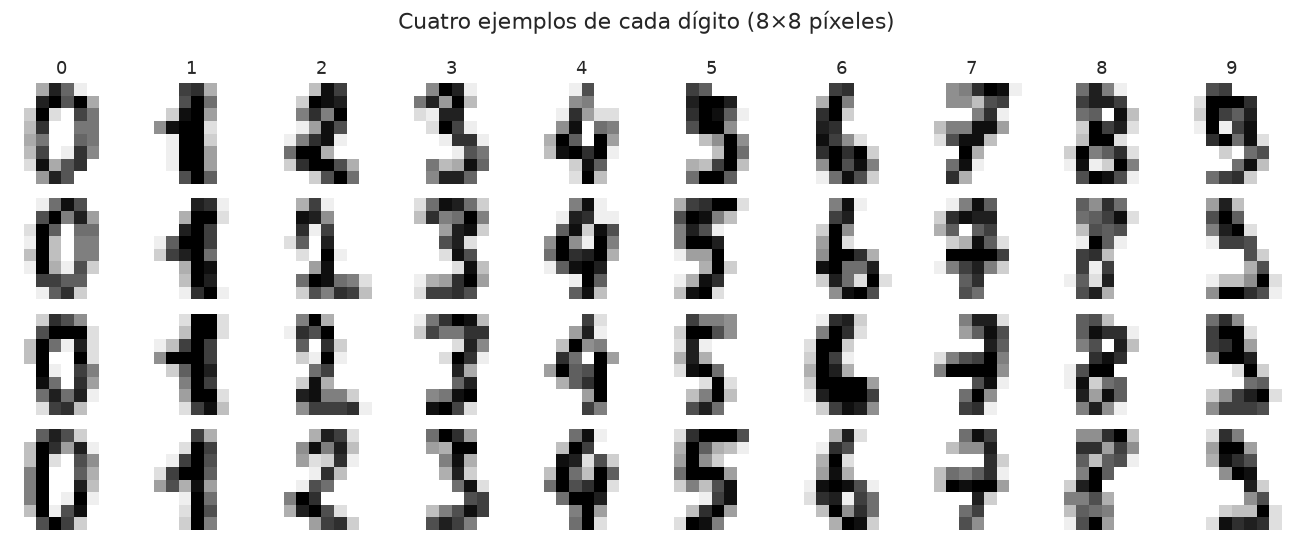

In [3]:
fig, axes = plt.subplots(4, 10, figsize=(12, 5))

for digito in range(10):
    indices = np.flatnonzero(y == digito)[:4]
    for fila, indice in enumerate(indices):
        ax = axes[fila, digito]
        ax.imshow(digits.images[indice], cmap="gray_r")
        ax.axis("off")
        if fila == 0:
            ax.set_title(str(digito))

fig.suptitle("Cuatro ejemplos de cada dígito (8×8 píxeles)")
plt.tight_layout()
plt.show()


Algunos dígitos son visualmente parecidos: un 8 con la parte superior abierta puede parecer un 1 o un
2, y un 1 inclinado se confunde con 4 o 6. Esas similitudes explican los errores del modelo final.


## 2. Particiones y preprocesamiento

Se replica el esquema del ejemplo: **60 % entrenamiento, 20 % validación y 20 % prueba**, estratificado.
La validación elige el modelo y la prueba se consulta una sola vez, al final.

Las intensidades se escalan con `StandardScaler` dentro de un `Pipeline`, ajustado solo con el
entrenamiento de cada partición para evitar filtración. El escalado importa porque
$z=\sum_i w_i x_i+b$ depende de la escala de entrada y las activaciones saturantes podrían arrancar
saturadas.


In [4]:
indices = np.arange(len(y))

i_desarrollo, i_test = train_test_split(
    indices, test_size=0.20, stratify=y, random_state=SEMILLA)
i_train, i_val = train_test_split(
    i_desarrollo, test_size=0.25, stratify=y[i_desarrollo], random_state=SEMILLA)

X_train, y_train = X_bruto[i_train], y[i_train]
X_val, y_val = X_bruto[i_val], y[i_val]
X_test, y_test = X_bruto[i_test], y[i_test]

assert len(set(i_train) & set(i_val)) == 0
assert len(set(i_train) & set(i_test)) == 0
assert len(set(i_val) & set(i_test)) == 0
assert len(set(i_train) | set(i_val) | set(i_test)) == len(y)

resumen = pd.DataFrame([
    {"Partición": "Entrenamiento (60 %)", "Total": len(y_train)},
    {"Partición": "Validación (20 %)", "Total": len(y_val)},
    {"Partición": "Prueba (20 %)", "Total": len(y_test)},
])
display(resumen)


,Partición,Total
0,Entrenamiento (60 %),1077
1,Validación (20 %),360
2,Prueba (20 %),360


## 3. Modelo y métricas

La red tiene 64 entradas, **una capa oculta de 100 neuronas** y 10 salidas `softmax`; en total
$64\cdot100+100+100\cdot10+10=7510$ parámetros. Las 100 neuronas son el valor por defecto de
scikit-learn y dan capacidad suficiente para las 1077 muestras de entrenamiento.

Todos los modelos comparten `solver="lbfgs"`, `alpha=1e-4`, `tol=1e-6`, `max_iter=2000` y
`max_fun=50000`; solo cambia la activación. Se registran las advertencias de convergencia porque un
modelo que agota las iteraciones no es comparable con uno que converge.

Métricas: accuracy; precisión, recall y F1 macro; kappa de Cohen (0 es azar, 1 acuerdo perfecto); log
loss; y Brier multiclase, $\frac{1}{n}\sum_i\sum_k (p_{ik}-y_{ik})^2$.


In [5]:
def construir_mlp(activacion, capas_ocultas=(100,)):
    return Pipeline([
        ("escala", StandardScaler()),
        ("mlp", MLPClassifier(
            hidden_layer_sizes=capas_ocultas,
            activation=activacion,
            solver="lbfgs",
            alpha=1e-4,
            tol=1e-6,
            max_iter=2000,
            max_fun=50000,
            random_state=SEMILLA
        )),
    ])


def brier_multiclase(etiquetas, probabilidades, clases):
    one_hot = np.zeros_like(probabilidades)
    for j, clase in enumerate(clases):
        one_hot[:, j] = (etiquetas == clase)
    return np.mean(np.sum((probabilidades - one_hot) ** 2, axis=1))


def evaluar(modelo, entradas, etiquetas):
    pred = modelo.predict(entradas)
    probabilidades = modelo.predict_proba(entradas)
    clases = np.asarray(modelo.classes_)
    return {
        "Accuracy": accuracy_score(etiquetas, pred),
        "Precisión macro": precision_score(etiquetas, pred, average="macro", zero_division=0),
        "Recall macro": recall_score(etiquetas, pred, average="macro", zero_division=0),
        "F1 macro": f1_score(etiquetas, pred, average="macro", zero_division=0),
        "Kappa": cohen_kappa_score(etiquetas, pred),
        "Log loss": log_loss(etiquetas, probabilidades, labels=clases),
        "Brier": brier_multiclase(etiquetas, probabilidades, clases),
    }


modelo_ejemplo = construir_mlp("relu")
print(f"MLP con capa oculta {modelo_ejemplo.named_steps['mlp'].hidden_layer_sizes}, "
      f"solver {modelo_ejemplo.named_steps['mlp'].solver}, "
      f"max_iter {modelo_ejemplo.named_steps['mlp'].max_iter}")


MLP con capa oculta (100,), solver lbfgs, max_iter 2000


## 4. Referencia de clase mayoritaria

Como referencia mínima, un clasificador que siempre predice el dígito más frecuente acierta ≈10 % y
tiene una log loss muy alta. Cualquier modelo útil debe superarlo por un margen amplio.


In [6]:
referencia = DummyClassifier(strategy="most_frequent")
referencia.fit(X_train, y_train)
print(pd.Series(evaluar(referencia, X_val, y_val)).round(4).to_string())


Accuracy            0.1028
Precisión macro     0.0103
Recall macro        0.1000
F1 macro            0.0186
Kappa               0.0000
Log loss           32.3392
Brier               1.7944


## 5. Comparación controlada en validación

Solo cambia la activación. Para cada una se mide el tiempo de `fit` con `time.perf_counter()`, se
cuentan las iteraciones y se capturan las advertencias de convergencia. L-BFGS no expone la pérdida por
iteración, así que la comparación usa métricas, iteraciones y tiempo total.


In [7]:
ACTIVACIONES = ["identity", "logistic", "tanh", "relu"]
modelos = {}
filas = []

for activacion in ACTIVACIONES:
    modelo = construir_mlp(activacion)

    inicio = time.perf_counter()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo.fit(X_train, y_train)
    segundos = time.perf_counter() - inicio

    convergencia = [a for a in avisos if issubclass(a.category, ConvergenceWarning)]
    entrenamiento = evaluar(modelo, X_train, y_train)
    validacion = evaluar(modelo, X_val, y_val)
    mlp = modelo.named_steps["mlp"]

    modelos[activacion] = modelo
    filas.append({
        "Activación": activacion,
        "Accuracy train": entrenamiento["Accuracy"],
        **validacion,
        "Iteraciones": mlp.n_iter_,
        "¿Convergió?": "no" if convergencia else "sí",
        "Segundos": segundos,
    })

    print(f"{activacion:9s} | iteraciones: {mlp.n_iter_:4d} | "
          f"convergió: {'no' if convergencia else 'sí':2s} | {segundos:.2f} s")

resultados = pd.DataFrame(filas).set_index("Activación")
display(resultados.round(4))


identity  | iteraciones:   24 | convergió: sí | 0.10 s


logistic  | iteraciones:   48 | convergió: sí | 0.36 s


tanh      | iteraciones:   21 | convergió: sí | 0.27 s
relu      | iteraciones:   23 | convergió: sí | 0.13 s


,Accuracy train,Accuracy,Precisión macro,Recall macro,F1 macro,Kappa,Log loss,Brier,Iteraciones,¿Convergió?,Segundos
Activación,,,,,,,,,,,
identity,1.0,0.9500,0.9501,0.9498,0.9497,0.9444,0.5319,0.0946,24,sí,0.1008
logistic,1.0,0.9778,0.9783,0.9778,0.9777,0.9753,0.0977,0.0359,48,sí,0.3628
tanh,1.0,0.9694,0.9698,0.9693,0.9693,0.9660,0.1202,0.0497,21,sí,0.2690
relu,1.0,0.9694,0.9701,0.9691,0.9693,0.9660,0.1678,0.0538,23,sí,0.1337


### Análisis de la comparación

- **`identity` es la peor:** 95.00 % frente a 96.94–97.78 % de las no lineales, y su log loss (0.53)
  triplica o cuadruplica la de `tanh` y `relu`. La red se comporta como un clasificador lineal: separa
  bastante bien porque los píxeles son informativos, pero no combina trazos en fronteras curvas.
- **`logistic` logra el mejor accuracy puntual (97.78 %)**, pero es la más lenta: 48 iteraciones.
  Su derivada máxima es 0.25 y su salida no está centrada en cero.
- **`tanh` y `relu` empatan (96.94 %)** con 21 y 23 iteraciones. Sus tiempos de décimas de segundo son
  ruidosos; la comparación fiable está en la sección 6.
- Los cuatro llegan al **100 % en entrenamiento**: con 7510 parámetros y 1077 muestras memorizan el
  conjunto, y la brecha con validación mide generalización.
- Ninguno agotó las iteraciones, así que todos convergieron.

Una partición de validación tiene 360 casos: un punto porcentual son menos de cuatro imágenes. Por eso
se repite la comparación con validación cruzada.


## 6. Robustez: validación cruzada repetida

La comparación anterior usa una sola partición y una sola inicialización; las diferencias entre las no
lineales (0.8 puntos) son del orden del error de estimación. Se repiten las cuatro activaciones con
**validación cruzada estratificada de 4 folds × 3 repeticiones** sobre el 80 % de desarrollo, sin tocar
prueba.


In [8]:
cv = RepeatedStratifiedKFold(n_splits=4, n_repeats=3, random_state=SEMILLA)
X_dev = np.vstack([X_train, X_val])
y_dev = np.hstack([y_train, y_val])

filas_cv = []

for activacion in ACTIVACIONES:
    accs, f1s, tiempos, iteraciones = [], [], [], []
    sin_converger = 0

    for idx_train, idx_val in cv.split(X_dev, y_dev):
        modelo = construir_mlp(activacion)

        inicio = time.perf_counter()
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always", ConvergenceWarning)
            modelo.fit(X_dev[idx_train], y_dev[idx_train])
        tiempos.append(time.perf_counter() - inicio)

        if any(issubclass(a.category, ConvergenceWarning) for a in avisos):
            sin_converger += 1

        iteraciones.append(modelo.named_steps["mlp"].n_iter_)
        pred = modelo.predict(X_dev[idx_val])
        accs.append(accuracy_score(y_dev[idx_val], pred))
        f1s.append(f1_score(y_dev[idx_val], pred, average="macro", zero_division=0))

    filas_cv.append({
        "Activación": activacion,
        "Accuracy media": np.mean(accs),
        "Desv. accuracy": np.std(accs),
        "F1 macro": np.mean(f1s),
        "Tiempo medio (s)": np.mean(tiempos),
        "Iteraciones": np.mean(iteraciones),
        "Sin converger": f"{sin_converger}/12",
    })

resultados_cv = pd.DataFrame(filas_cv).set_index("Activación")
display(resultados_cv.round(4))


,Accuracy media,Desv. accuracy,F1 macro,Tiempo medio (s),Iteraciones,Sin converger
Activación,,,,,,
identity,0.9531,0.0094,0.9531,0.0827,22.5833,0/12
logistic,0.9703,0.0090,0.9702,0.3378,45.0833,0/12
tanh,0.9680,0.0096,0.9679,0.1852,19.8333,0/12
relu,0.9699,0.0112,0.9698,0.1095,22.5833,0/12


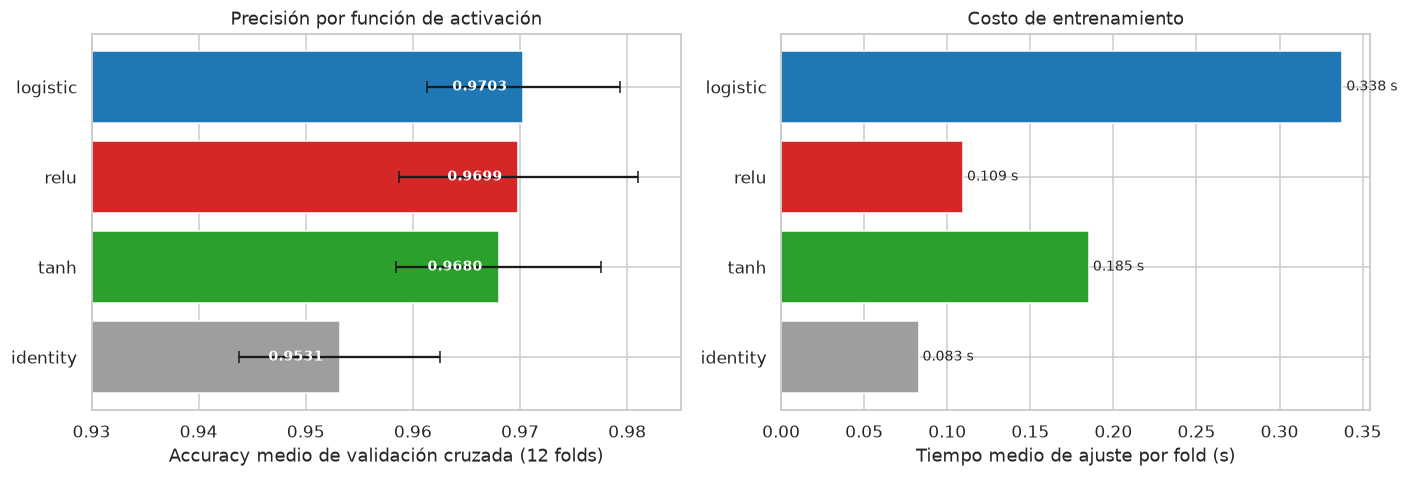

In [9]:
colores = {"identity": "#9e9e9e", "logistic": "#1f77b4", "tanh": "#2ca02c", "relu": "#d62728"}
orden = resultados_cv.sort_values("Accuracy media", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].barh(orden.index, orden["Accuracy media"], xerr=orden["Desv. accuracy"],
             capsize=4, color=[colores[a] for a in orden.index])
axes[0].set_xlim(0.93, 0.985)
axes[0].set_xlabel("Accuracy medio de validación cruzada (12 folds)")
axes[0].set_title("Precisión por función de activación")
for i, valor in enumerate(orden["Accuracy media"]):
    axes[0].text(valor - 0.0015, i, f"{valor:.4f}", va="center", ha="right",
                 color="white", fontsize=9, fontweight="bold")

axes[1].barh(orden.index, orden["Tiempo medio (s)"],
             color=[colores[a] for a in orden.index])
axes[1].set_xlabel("Tiempo medio de ajuste por fold (s)")
axes[1].set_title("Costo de entrenamiento")
for i, valor in enumerate(orden["Tiempo medio (s)"]):
    axes[1].text(valor, i, f" {valor:.3f} s", va="center", fontsize=9)

plt.tight_layout()
plt.show()


### Lectura de la validación cruzada

- **`identity` queda claramente por debajo (95.31 %)**: la falta de no linealidad es una limitación real.
- **`logistic` (97.03 %), `relu` (96.99 %) y `tanh` (96.80 %)** difieren en 0.23 puntos, menos que su
  desviación típica (≈0.9–1.1): no hay evidencia para afirmar que una sea más precisa.
- **El tiempo sí las separa:** `logistic` tarda ≈0.3 s por fold, alrededor de 3 veces `relu` (≈0.1 s).
  `tanh` tarda ≈0.19 s: menos iteraciones (19.8 frente a 22.6), pero cada una más costosa por las
  exponenciales.
- Ningún ajuste agotó las 2000 iteraciones en los 48 entrenamientos.

La conclusión práctica: la no linealidad importa frente a `identity`, pero entre las tres no lineales
decide el costo.


### Regla de selección

La regla se fija antes de consultar la prueba:

1. Mayor accuracy medio de validación cruzada.
2. Son candidatas las que estén a menos de una desviación típica del máximo (criterio heurístico).
3. Entre ellas, la de menor tiempo medio de entrenamiento.

Así no se premia una diferencia que no es distinguible y se incorpora el costo de entrenamiento.


In [10]:
mejor_accuracy = resultados_cv["Accuracy media"].max()
desviacion = resultados_cv.loc[resultados_cv["Accuracy media"].idxmax(), "Desv. accuracy"]
umbral = mejor_accuracy - desviacion

candidatas = resultados_cv[resultados_cv["Accuracy media"] >= umbral]
MEJOR_ACTIVACION = candidatas["Tiempo medio (s)"].idxmin()

print(f"Mejor accuracy medio: {mejor_accuracy:.4f} ± {desviacion:.4f}")
print(f"Umbral para considerar una diferencia como ruido: {umbral:.4f}")
print(f"Activaciones candidatas: {', '.join(candidatas.index)}")
print(f"Activación seleccionada (menor tiempo entre las candidatas): {MEJOR_ACTIVACION}")


Mejor accuracy medio: 0.9703 ± 0.0090
Umbral para considerar una diferencia como ruido: 0.9613
Activaciones candidatas: logistic, tanh, relu
Activación seleccionada (menor tiempo entre las candidatas): relu


## 7. Evaluación final en el conjunto de prueba

Con la activación elegida se entrena el modelo definitivo sobre todo el 80 % de desarrollo —la
validación ya cumplió su función— y se evalúa una única vez en el 20 % de prueba.


In [11]:
modelo_final = construir_mlp(MEJOR_ACTIVACION)

inicio = time.perf_counter()
modelo_final.fit(X_dev, y_dev)
tiempo_final = time.perf_counter() - inicio
mlp_final = modelo_final.named_steps["mlp"]

y_pred = modelo_final.predict(X_test)
metricas_test = evaluar(modelo_final, X_test, y_test)

print(f"Modelo final: MLP(100) con activación = {MEJOR_ACTIVACION}")
print(f"Entrenado con {len(y_dev)} imágenes en {tiempo_final:.2f} s "
      f"({mlp_final.n_iter_} iteraciones)")
print()
print(pd.Series(metricas_test).round(4).to_string())
print()
print(classification_report(y_test, y_pred, digits=4))


Modelo final: MLP(100) con activación = relu
Entrenado con 1437 imágenes en 0.29 s (23 iteraciones)

Accuracy           0.9667
Precisión macro    0.9662
Recall macro       0.9663
F1 macro           0.9659
Kappa              0.9630
Log loss           0.3933
Brier              0.0606

              precision    recall  f1-score   support

           0     0.9722    0.9722    0.9722        36
           1     0.9143    0.8889    0.9014        36
           2     0.9211    1.0000    0.9589        35
           3     1.0000    1.0000    1.0000        37
           4     0.9722    0.9722    0.9722        36
           5     1.0000    1.0000    1.0000        37
           6     0.9722    0.9722    0.9722        36
           7     1.0000    1.0000    1.0000        36
           8     0.9375    0.8571    0.8955        35
           9     0.9730    1.0000    0.9863        36

    accuracy                         0.9667       360
   macro avg     0.9662    0.9663    0.9659       360
weighted avg

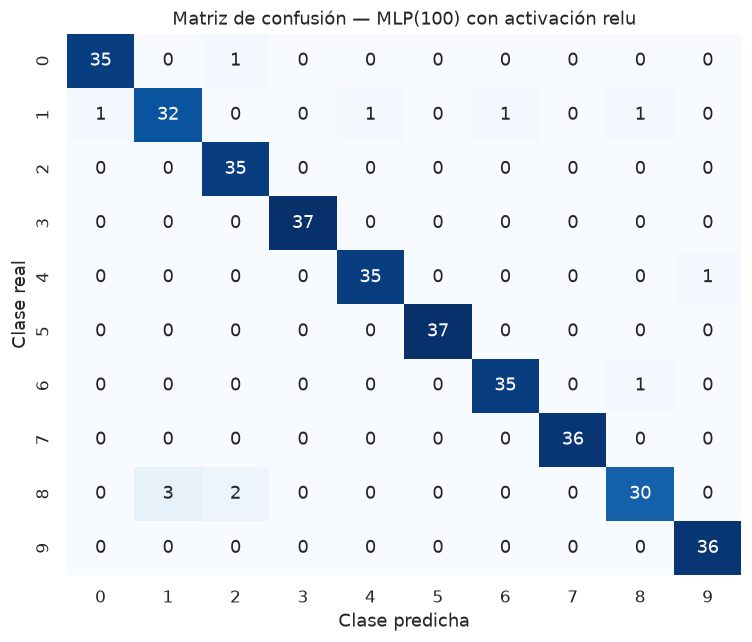

Confusiones más frecuentes (real → predicho):
  8 → 1: 3 casos
  8 → 2: 2 casos
  6 → 8: 1 caso
  4 → 9: 1 caso
  0 → 2: 1 caso


In [12]:
matriz = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=range(10), yticklabels=range(10), ax=ax)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title(f"Matriz de confusión — MLP(100) con activación {MEJOR_ACTIVACION}")
plt.tight_layout()
plt.show()

errores = matriz.copy()
np.fill_diagonal(errores, 0)
pares = np.dstack(np.unravel_index(np.argsort(errores.ravel())[::-1][:5], errores.shape))[0]
print("Confusiones más frecuentes (real → predicho):")
for real, predicho in pares:
    if errores[real, predicho] > 0:
        print(f"  {real} → {predicho}: {errores[real, predicho]} "
              f"{'caso' if errores[real, predicho] == 1 else 'casos'}")


El modelo final obtiene **96.67 % de accuracy**, F1 macro de 96.59 % y kappa de 0.963. Los 12 errores
se concentran en el **8**, confundido con **1** (3 casos) y **2** (2 casos), y en el **1**, disperso
entre 0, 4, 6 y 8: son los pares de trazos más parecidos.

La accuracy de prueba es coherente con la validación cruzada (96.99 %); la diferencia de 0.32 puntos
cabe en la variabilidad de 360 casos. En entrenamiento llega al 100 %: la brecha de 3.33 puntos refleja
un sobreajuste leve por los 7510 parámetros y la regularización suave, pero no impide generalizar.


## 8. Conclusiones

1. **La no linealidad es imprescindible.** `identity` deja la red como clasificador lineal: 95.31 % de
   accuracy medio y log loss 0.53, con una tasa de error 1.6 veces mayor que las otras activaciones.

2. **Entre las no lineales no hay ganador estadístico.** `logistic` (97.03 %), `relu` (96.99 %) y
   `tanh` (96.80 %) difieren en 0.23 puntos, menos que la desviación típica (≈0.9–1.1). La aparente
   ventaja de `logistic` en el split único era ruido.

3. **`relu` es la elección recomendada por tiempo.** Con precisión indistinguible, es la más barata de
   las tres: ≈0.1 s por fold frente a ≈0.3 s de `logistic` (unas 3 veces más) y ≈0.19 s de `tanh`.
   Su derivada vale 1 en la región activa y se calcula con una comparación.

4. **`logistic` no se justifica en las capas ocultas.** Necesita 45.1 iteraciones de L-BFGS frente a
   22.6 de `relu`, por su derivada máxima de 0.25 y su falta de centrado. Su lugar natural es la salida
   binaria.

5. **`tanh` es una alternativa cercana:** menos iteraciones (19.8), pero más costosas por las
   exponenciales y precisión prácticamente igual.

6. **Resultado final:** 96.67 % de accuracy, 96.59 % de F1 macro y kappa 0.963 en prueba, con errores
   en 8→1, 8→2 y en el 1. Limitaciones: dataset pequeño, una arquitectura y una semilla; una red
   convolucional o características HOG aprovecharían la estructura espacial.
